In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
print("Notebook cwd:", cwd)

project_root = cwd
while not (project_root / "analysis").exists():
    if project_root.parent == project_root:
        raise RuntimeError("Could not find project root containing 'analysis'")
    project_root = project_root.parent

sys.path.insert(0, str(project_root))
print("Added project root to sys.path:", project_root)

import analysis
print("analysis loaded from:", analysis.__file__)


Notebook cwd: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/notebooks
Added project root to sys.path: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator
analysis loaded from: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/__init__.py


In [2]:
from pathlib import Path

from analysis import (
    BatchLoader,
    ExperimentAggregator,
    StatisticalAnalyzer,
    TrajectoryVisualizer,
    HeatmapVisualizer,
    MetricsVisualizer
)

In [3]:
PROJECT_ROOT = project_root
EXPERIMENTS_DIR = PROJECT_ROOT / "experiments"
REPORT_DIR = PROJECT_ROOT / "report"

print("Project root:", PROJECT_ROOT)
print("Experiments dir:", EXPERIMENTS_DIR)
print("Report dir:", REPORT_DIR)

Project root: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator
Experiments dir: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/experiments
Report dir: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report


In [4]:
batch = BatchLoader(EXPERIMENTS_DIR)
experiments = batch.load_all()

print(f"Loaded {len(experiments)} experiments")

experiments[0] if experiments else "No experiments loaded"

✓ Loaded Experiment(run_id=0a908ac5, seed=1768316351, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=0bf5db3f, seed=1768317098, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=277cd7df, seed=1768307693, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=47f812cc, seed=1768307033, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=5524343c, seed=1768319703, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=5f8808dc, seed=1768316916, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=6cdf33ad, seed=1768317901, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=8007ce60, seed=1768306032, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=9a564e21, seed=1768318770, strategies=6, agents=4, parcels=8)
✓ Loaded Experiment(run_id=bb3e572f, seed=1768277105, strategies=6, agents=4, parcels=8)
Loaded 10 experiments


Experiment(run_id=0a908ac5, seed=1768316351, strategies=6, agents=4, parcels=8)

In [5]:
agg = ExperimentAggregator(experiments)

df = agg.dataframe
df.head()

,run_id,seed,strategy_name,planner,mission_makespan_steps,total_energy_consumed,total_distance_traveled,tasks_completed,unsafe_failures,messages_sent,...,energy_per_task,distance_per_task,efficiency_ratio,failure_rate,n_drones,n_parcels,comm_reliability,battery_capacity,n_collisions,parcels_delivered
0,0a908ac5,1768316351,naive_decentralized,local,976,67.152,27.0,8,353,0,...,8.394000,3.375,0.402073,44.125,4,8,1.0,100.0,353,8
1,0a908ac5,1768316351,centralized_cc,local,618,43.113,19.0,8,60,0,...,5.389125,2.375,0.440702,7.500,4,8,1.0,100.0,60,8
2,0a908ac5,1768316351,sppdec_control,local,622,63.954,29.0,8,352,0,...,7.994250,3.625,0.453451,44.000,4,8,1.0,100.0,352,8
3,0a908ac5,1768316351,sppdec_baseline_only,local,475,48.681,26.0,8,116,0,...,6.085125,3.250,0.534089,14.500,4,8,1.0,100.0,116,8
4,0a908ac5,1768316351,sppdec_fairness_only,local,540,55.461,28.0,8,87,0,...,6.932625,3.500,0.504859,10.875,4,8,1.0,100.0,87,8


In [6]:
summary = agg.summary()
summary

mission_makespan_steps                     \
                                       mean     std  min   max   
strategy_name                                                    
centralized_cc                        570.0   68.33  472   674   
naive_decentralized                   945.1  192.06  659  1278   
sppdec_baseline_only                  649.7  112.50  475   765   
sppdec_combined                       614.9  136.49  382   785   
sppdec_control                        594.9   92.88  422   758   
sppdec_fairness_only                  657.2  190.09  392   924   

                     total_energy_consumed                       \
                                      mean    std    min    max   
strategy_name                                                     
centralized_cc                       43.94   2.95  39.00  48.59   
naive_decentralized                  70.93  11.62  53.80  91.53   
sppdec_baseline_only                 64.28   8.01  48.68  72.95   
sppdec_combined                      63.45   7.42  50.50  72.77   
sppdec_control                       61.66   7.29  52.11  75.54   
sppdec_fairness_only                 61.97  10.80  50.01  77.81   

                     total_distance_traveled        ... energy_per_task  \
                                        mean   std  ...             cv%   
strategy_name                                       ...                   
centralized_cc                          18.5  0.71  ...             6.7   
naive_decentralized                     30.3  2.36  ...            16.4   
sppdec_baseline_only                    28.6  2.22  ...            12.5   
sppdec_combined                         28.0  1.76  ...            11.7   
sppdec_control                          28.2  1.81  ...            11.8   
sppdec_fairness_only                    27.7  1.95  ...            17.4   

                     distance_per_task efficiency_ratio failure_rate n_drones  \
                                   cv%              cv%          cv%      cv%   
strategy_name                                                                   
centralized_cc                     3.8              4.8         92.2      0.0   
naive_decentralized                7.8             14.0         40.1      0.0   
sppdec_baseline_only               7.8              9.3         58.1      0.0   
sppdec_combined                    6.3              8.6         49.2      0.0   
sppdec_control                     6.4              9.1         34.9      0.0   
sppdec_fairness_only               7.0             12.0         66.3      0.0   

                     n_parcels comm_reliability battery_capacity n_collisions  \
                           cv%              cv%              cv%          cv%   
strategy_name                                                                   
centralized_cc             0.0              0.0              0.0         92.2   
naive_decentralized        0.0              0.0              0.0         40.1   
sppdec_baseline_only       0.0              0.0              0.0         58.1   
sppdec_combined            0.0              0.0              0.0         49.2   
sppdec_control             0.0              0.0              0.0         34.9   
sppdec_fairness_only       0.0              0.0              0.0         66.3   

                     parcels_delivered  
                                   cv%  
strategy_name                           
centralized_cc                     0.0  
naive_decentralized                0.0  
sppdec_baseline_only               0.0  
sppdec_combined                    0.0  
sppdec_control                     0.0  
sppdec_fairness_only               0.0  

[6 rows x 85 columns]

In [7]:
analyzer = StatisticalAnalyzer(agg)

analyzer.pairwise_ttest(
    metric="mission_makespan_steps",
    baseline_strategy="sppdec_combined"
)

,comparison_strategy,baseline_mean,comparison_mean,difference,pct_difference,t_statistic,p_value,significance,cohens_d,n_baseline,n_comparison
0,naive_decentralized,614.9,945.1,330.2,53.6998,-4.4316,0.0003,***,-1.9819,10,10
1,centralized_cc,614.9,570.0,-44.9,-7.3020,0.9302,0.3646,ns,0.4160,10,10
2,sppdec_control,614.9,594.9,-20.0,-3.2526,0.3831,0.7061,ns,0.1713,10,10
3,sppdec_baseline_only,614.9,649.7,34.8,5.6595,-0.6222,0.5416,ns,-0.2782,10,10
4,sppdec_fairness_only,614.9,657.2,42.3,6.8792,-0.5716,0.5747,ns,-0.2556,10,10


Generating statistical report...
✓ Summary statistics
✓ ANOVA results
✓ Saved boxplot: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report/boxplot_mission_makespan_steps.png


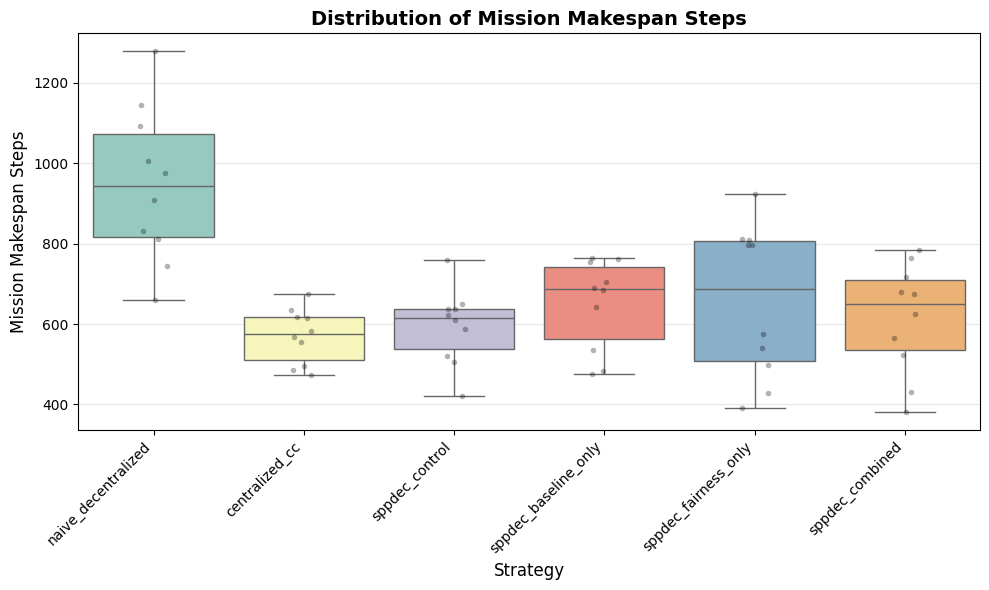

✓ Saved boxplot: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report/boxplot_total_energy_consumed.png


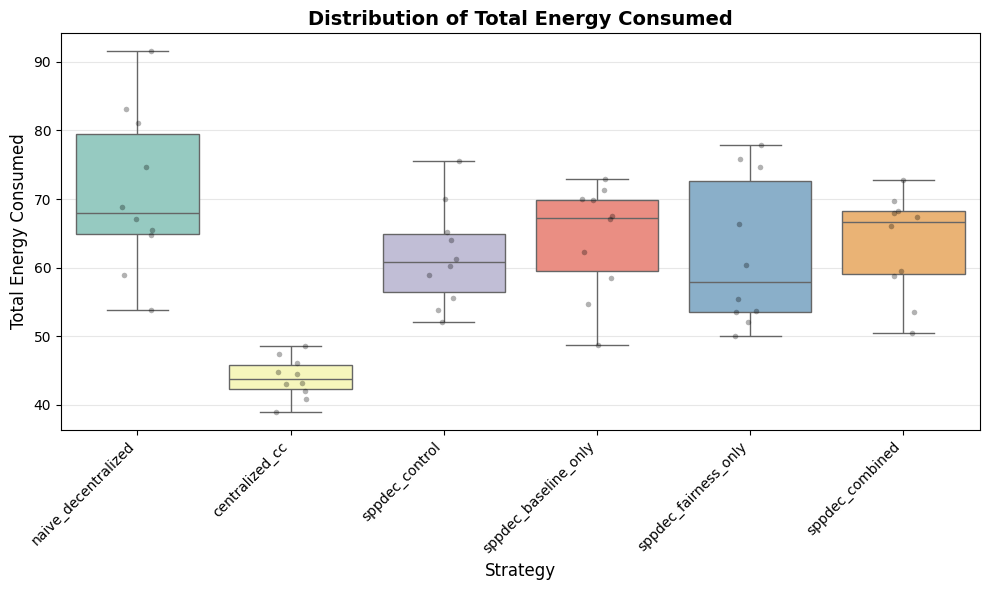

✓ Saved boxplot: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report/boxplot_total_distance_traveled.png


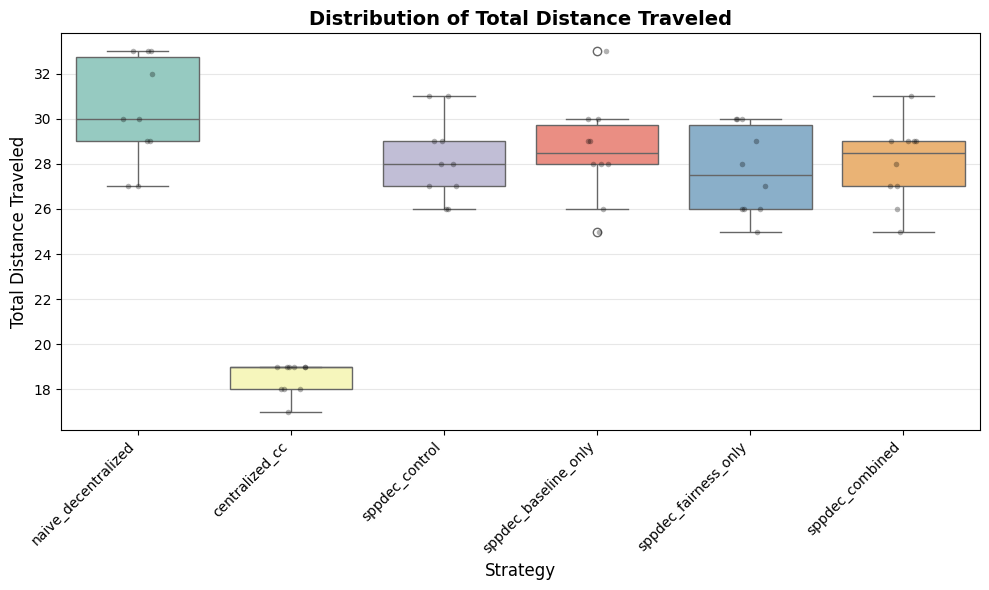

✓ Saved boxplot: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report/boxplot_unsafe_failures.png


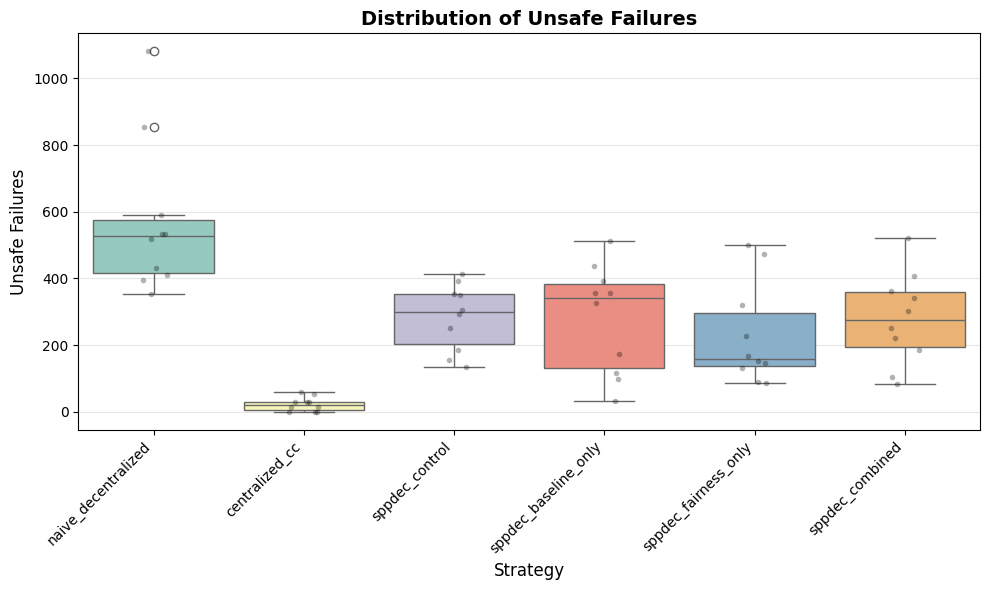


✓ Report generated in: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report


In [8]:
analyzer.generate_report(REPORT_DIR)

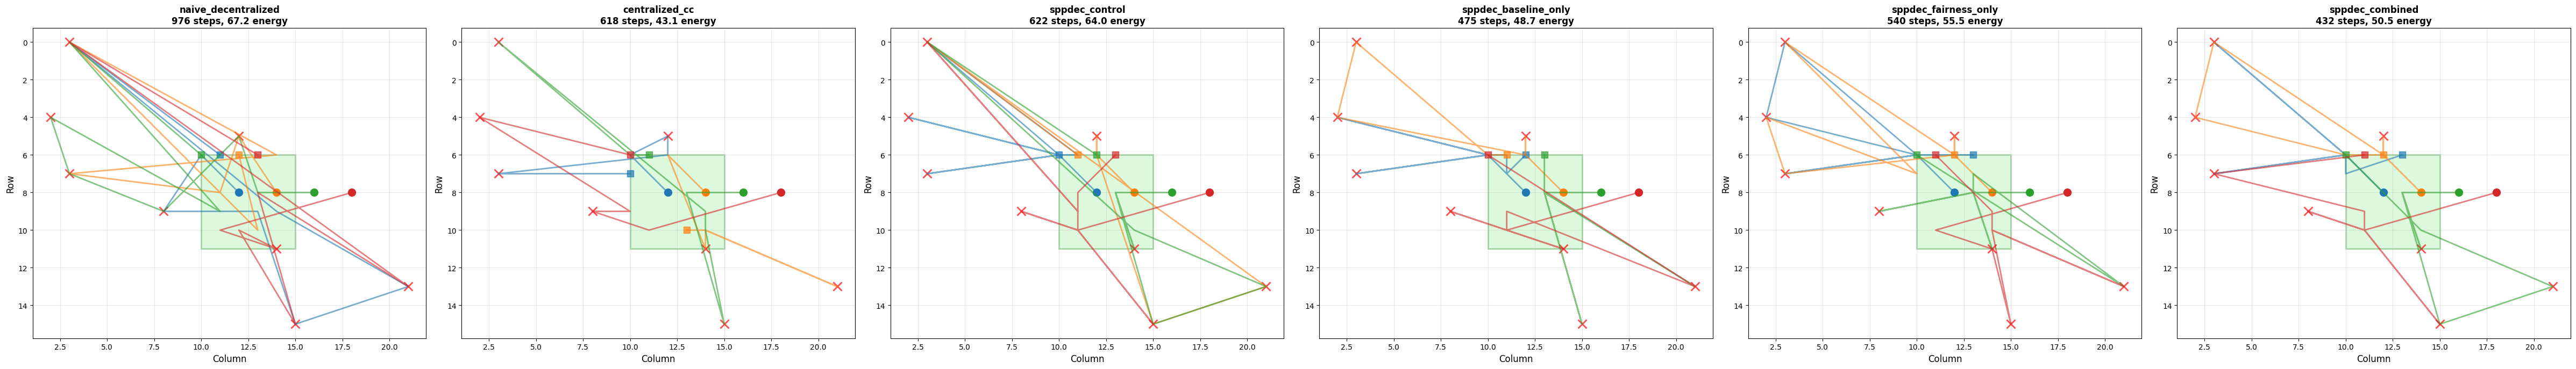

In [9]:
if experiments:
    exp = experiments[0]

    viz = TrajectoryVisualizer()
    viz.plot_comparison(
        experiment=exp,
        strategy_names=[s.strategy_name for s in exp.strategies]
    )

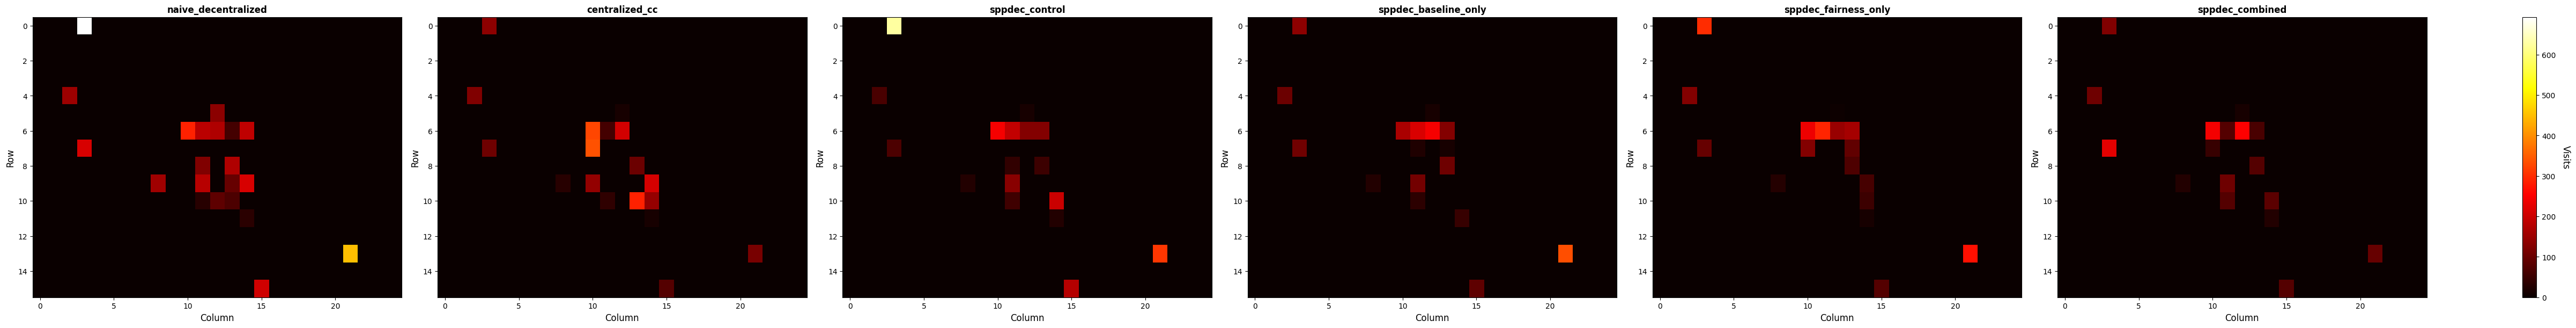

In [10]:
if experiments:
    heat = HeatmapVisualizer()

    heat.plot_comparison(
        experiment=exp,
        strategy_names=[s.strategy_name for s in exp.strategies]
    )

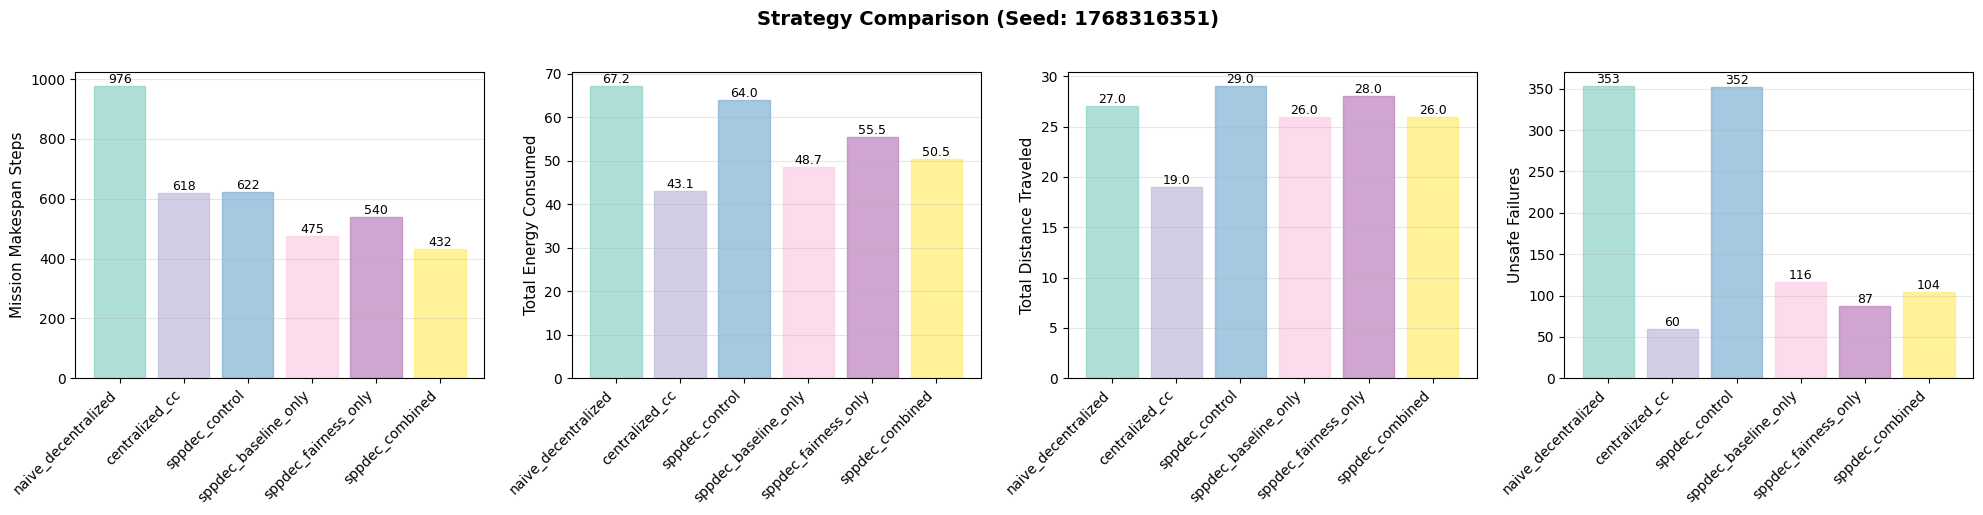

In [11]:
if experiments:
    metrics_viz = MetricsVisualizer()
    metrics_viz.plot_comparison(exp)